In [2]:
import pandas as pd
import seaborn as sns
from six_nations_fantasy.score import score

In [4]:
performances = pd.read_parquet('../tests/all_data_performances.parquet')
performances['score'] = performances.apply(score, axis=1)

In [5]:
performances \
    .loc[performances['position'] != 'R'] \
    .groupby('position') \
    .apply(lambda grp: grp['score'].mean())

position
       0.000000
C     13.720536
FB    15.587273
FH    16.521739
FL    12.830009
H      9.097015
L      9.767600
N8    14.886486
P      7.045633
SH     9.489264
W     14.419833
dtype: float64

<Axes: xlabel='score', ylabel='Count'>

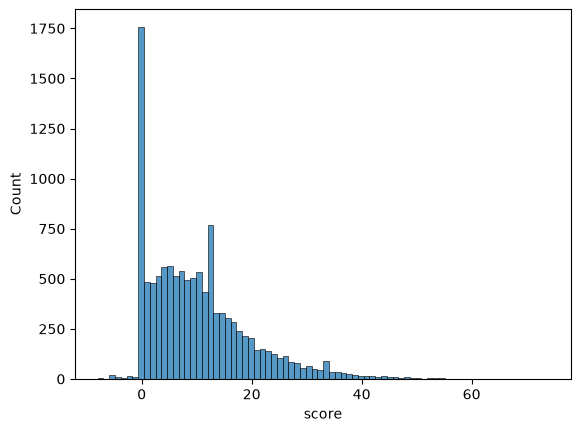

In [6]:
fh = performances['score']
sns.histplot(fh)

<Axes: ylabel='Count'>

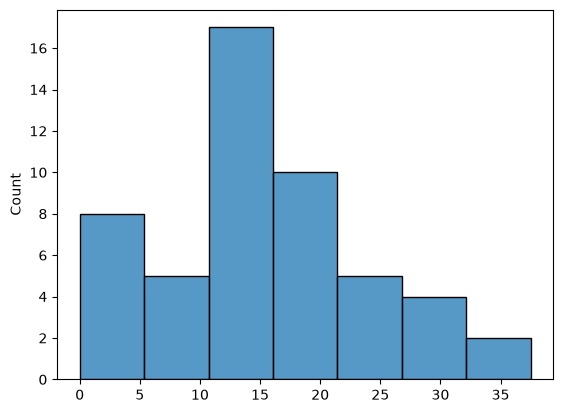

In [7]:
fh = performances[performances['position'] == 'FH'] \
    .groupby('name') \
    .filter(lambda grp: grp.shape[0] >= 2) \
    .groupby('name') \
    .apply(lambda grp: grp['score'].mean())
sns.histplot(fh)